# Lumped Josephson parametric amplifiers with VACASK

::::{admonition} Required extras
:class: tip

Needs `models` and the external
[VACASK](https://codeberg.org/arpadbuermen/VACASK) simulator:
`uv sync --extra models` (or `pip install "qpdk[models]"`). Install VACASK,
put `vacask` on `PATH` or set `VACASK`; it compiles Verilog-A with the bundled
`openvaf-r`, and Linux also needs `binutils`. See the
{ref}`extras reference <notebook-extras>`.
::::

A parametric amplifier uses a strong pump and a nonlinear inductance to
amplify a weak signal
{cite:p}`clerkIntroductionQuantumNoise2010,royIntroductionParametricAmplification2016`.
The pump creates gain. It also creates idlers: a signal at $f_\text{s}$
produces waves at $f_\text{s} + k f_\text{p}$.

A classical simulation needs two steps. First find the pumped steady state
with harmonic balance, HB
{cite:p}`kundertSimulationNonlinearCircuits1986`. Then find the small-signal
waves around that state. In VACASK the second step is `hbac`, a
conversion-matrix analysis {cite:p}`maasNonlinearMicrowaveRF2003`. The
{ref}`vacask-analysis-guide` below compares these analyses.

This notebook runs the two lumped examples in released VACASK: a
current-pumped Kerr junction with four-wave mixing, and a flux-pumped SQUID
with three-wave mixing. It ends with signal compression. The
{doc}`TWPA notebook <josephsoncircuits_twpa>` covers the traveling-wave
circuit with JosephsonCircuits.jl. The
{doc}`CPW companion <vacask_cpw_parametric_amplifier>` qualifies
the distributed resonator model.

The schematic shows the Kerr circuit on the left and the distributed
flux-pumped circuit from the CPW companion on the right. The lumped flux
example replaces the line with a shunt capacitor.

![A current-pumped Kerr JPA (junction and shunt capacitor coupled to a 50 Ω port) and a flux-pumped JPA (quarter-wave CPW terminated in a SQUID whose flux is modulated)](figures/vacask-jpa-circuits.svg)

(vacask-analysis-guide)=
## Choose a VACASK analysis

An analysis chooses the circuit problem to solve. VACASK then uses numerical
methods such as Newton iteration or time stepping to solve it. The manual
groups the analyses by the state they use {cite:p}`vacaskCircuitAnalyses`.

| Question | Analysis | State and result |
| --- | --- | --- |
| What is the DC state? | `op` | Solve the nonlinear DC equations. |
| What is the unpumped response? | `ac`, `acsp` | Linearize at a DC state. `ac` returns voltages and currents; `acsp` returns port S-parameters. |
| What happens in time? | `tran` | Integrate the nonlinear equations, including startup and transients. |
| What periodic state repeats in time? | `pss` | Use shooting to match the state after one period to its initial state. |
| What weak signal responds to that state? | `pac` | Linearize around a shooting-based periodic state. |
| What is the periodic pump spectrum? | `hb` | Solve for Fourier coefficients using harmonic balance. |
| What weak signal and idlers respond to the pump? | `hbac` | Linearize around an HB state and couple its frequency sidebands. |

The manual also covers transfer functions, feedback-loop analysis and noise.
`noise` uses a DC state and `hbnoise` uses an HB state. Those are classical
device-noise calculations. They do not by themselves give quantum added
noise. The current manual includes features that an installed release may
lack.

For a parametric amplifier, use `hb` for the pump, then `hbac` for the weak
probe. `hbac` labels the response at $f_\text{s}+k f_\text{p}$.

In [1]:
import sys

if "google.colab" in sys.modules:
    import subprocess

    print("Running in Google Colab. Installing dependencies...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "qpdk[models] @ git+https://github.com/gdsfactory/quantum-rf-pdk.git",
    ])

In [2]:
import os
import time
from pathlib import Path

import jax
import jax.numpy as jnp
from jax.typing import ArrayLike
from matplotlib import font_manager, pyplot as plt

import qpdk.colormaps  # ruff: ignore[unused-import] - registers the style colormap
from qpdk import PDK
from qpdk.config import PATH
from qpdk.simulation.vacask import (
    Netlist,
    Vacask,
    VacaskError,
    format_value,
)

# Agg suppresses notebook figure outputs in headless CI.
if "ipykernel" in sys.modules:
    from IPython import get_ipython
    from matplotlib_inline.backend_inline import set_matplotlib_formats

    if (ipython := get_ipython()) is not None:
        ipython.run_line_magic("matplotlib", "inline")
        set_matplotlib_formats("png", "svg")

jax.config.update("jax_enable_x64", True)
PDK.activate()

# The checkout stylesheet is absent from installed wheels.
for _style in (PATH.docs / "qpdk.mplstyle", "qpdk"):
    try:
        plt.style.use(_style)
    except OSError:
        continue
    break

# The stylesheet names fonts that only the docs build ships; register them so
# they resolve without docs/ipython_config.py.
_font_dir = os.environ.get("QPDK_DOCS_FONTS_DIR")
for _fonts in (Path(_font_dir) if _font_dir else None, PATH.repo / "build/docs-fonts"):
    if _fonts is not None and _fonts.is_dir():
        for _font in sorted(_fonts.iterdir()):
            if _font.suffix in {".otf", ".ttf"}:
                font_manager.fontManager.addfont(str(_font))
        break

## Finding VACASK

{meth}`Vacask.find() <qpdk.simulation.vacask.Vacask.find>` checks the
`VACASK`/`QPDK_VACASK` environment variables and `PATH`. The notebook stops
if the binary is missing.

In [3]:
try:
    vacask = Vacask.find()
except VacaskError as error:
    print(error)
    raise SystemExit(
        "VACASK is not installed; skipping the rest of this notebook."
    ) from None
print(f"Using VACASK at {vacask.binary}")

Using VACASK at <runtime>


Every netlist uses `tolscale=1e-6 reltol=1e-6`. The default tolerances shift
the gain by more than the differences resolved here. Port conventions:

- A port is a Norton source $I_\text{s}$ in parallel with $R=50\,\Omega$.
  So $V_\text{inc}=I_\text{s}R/2$ and $\Gamma=2V/(I_\text{s}R)-1$
  {cite:p}`m.pozarMicrowaveEngineering2012`.
- VACASK reports a `sine` source of amplitude $A$ as $-\text{j}A$, so the
  incident HB phasor is $-\text{j}I_\text{s}R/2$.
- `hbac` writes the response at $f_\text{s}+k f_\text{p}$ as `node;k`.

In [4]:
R_PORT = 50.0
I_SIG = 1e-9
OPTIONS = "options tolscale=1e-6 reltol=1e-6"

# Kerr junction; both circuits share the 2 pF shunt.
IC, C_SHUNT = 1e-6, 2e-12


def db(x: ArrayLike) -> jax.Array:
    r"""Power gain in dB of a wave amplitude ratio, :math:`20\log_{10}|A|`. See :cite:p:`m.pozarMicrowaveEngineering2012`."""
    return 20 * jnp.log10(jnp.abs(x))


def reflection(v: ArrayLike, source_current: float) -> jax.Array:
    r"""Reflection coefficient of a Norton port from its node voltage.

    Uses :math:`\Gamma=2V/(I_\text{s}R)-1`
    :cite:p:`m.pozarMicrowaveEngineering2012`.

    Returns:
        Complex reflected wave amplitude divided by the incident amplitude.
    """
    return 2 * jnp.asarray(v) / (source_current * R_PORT) - 1


def conversion(v: ArrayLike, source_current: float) -> jax.Array:
    r"""Conversion gain into a sideband other than the one driven.

    The sideband amplitude is :math:`2V/(I_\text{s}R)`, as in
    frequency-conversion analysis :cite:p:`maasNonlinearMicrowaveRF2003`.

    Returns:
        Complex sideband wave amplitude divided by the incident amplitude.
    """
    return 2 * jnp.asarray(v) / (source_current * R_PORT)


def resonance(f: jax.Array, gamma: jax.Array) -> tuple[jax.Array, jax.Array]:
    r"""Peak-delay frequency and :math:`\kappa/2\pi` of a lossless one-port.

    Group delay is :math:`\tau=-\text{d}\arg\Gamma/\text{d}\omega`, which peaks
    at :math:`4/\kappa` on resonance :cite:p:`m.pozarMicrowaveEngineering2012`.

    Returns:
        Resonance frequency and linewidth, both in Hz.
    """
    grad = jnp.gradient(jnp.unwrap(jnp.angle(gamma)), 2 * jnp.pi * f)
    tau = -jnp.asarray(grad[0] if isinstance(grad, list) else grad)
    k = tau.argmax()
    return f[k], 4 / tau[k] / (2 * jnp.pi)


def show_plot() -> None:
    """Show the current figure with Outfit titles, as the docs config does."""
    fig = plt.gcf()
    for text in [ax.title for ax in fig.axes] + list(fig.texts):
        if text.get_text():
            text.set_fontfamily("Outfit")
            text.set_fontweight("bold")
    plt.show()

## Current-pumped Kerr JPA

A 1 µA junction with a 2 pF shunt is coupled to the 50 Ω port through
0.185 pF. The junction is a nonlinear inductor. Expanding
$I=I_\text{c}\sin\varphi$ for a junction current
$I_\text{p}\cos\omega_\text{p}t$ gives the first-harmonic inductance

```{math}
:label: eq:vacask-kerr-inductance
L_\text{J}(I_\text{p}) \simeq L_\text{J}\left(1+\frac{I_\text{p}^2}{8I_\text{c}^2}\right),
\qquad L_\text{J}=\frac{\Phi_0}{2\pi I_\text{c}} = 329\,\text{pH}.
```

A stronger pump therefore lowers the resonance. This Kerr shift is why the
pump at 5.84 GHz sits below the unpumped resonance measured below. The pump
also modulates $L_\text{J}$ at $2f_\text{p}$. A signal at $f_\text{p}+\delta$ is
amplified, with an idler at $f_\text{p}-\delta$. This is four-wave mixing,
$2f_\text{p}=f_\text{s}+f_\text{i}$
{cite:p}`royIntroductionParametricAmplification2016,eichlerControllingDynamicRange2014`.

The pump source injects the signal on its first-harmonic spur (`spur={[1]}`).
So `in;1` is the reflected signal and `in;-1` is the idler.

`hbac` treats the signal as infinitesimal around the pump. It returns the
signal and idler as a linear response to the pumped state. By default it also
solves the HB for the pump, so no separate HB run is needed here. See the
{ref}`vacask-analysis-guide`.

unpumped f0 = 5.9598 GHz, κ/2π = 158.1 MHz, pump detuning (f_p - f0)/(κ/2π) = -0.76


5 pump amplitudes × 80 offsets in 0.26 s


findfont: Failed to find font weight bold, now using 400.


I_p =  38.0 nA: G =   4.20 dB, idler   2.13 dB at 0.5 MHz; G =   4.17 dB at 5 MHz; signed photon sum = 0.999998
I_p =  40.0 nA: G =  11.81 dB, idler  11.51 dB at 0.5 MHz; G =  11.50 dB at 5 MHz; signed photon sum = 0.999995
I_p =  41.0 nA: G =  23.08 dB, idler  23.05 dB at 0.5 MHz; G =  20.78 dB at 5 MHz; signed photon sum = 0.999987
I_p =  42.0 nA: G =  16.95 dB, idler  16.86 dB at 0.5 MHz; G =  16.61 dB at 5 MHz; signed photon sum = 0.999995
I_p = 100.0 nA: G =   1.16 dB, idler  -5.13 dB at 0.5 MHz; G =   1.16 dB at 5 MHz; signed photon sum = 1.000000


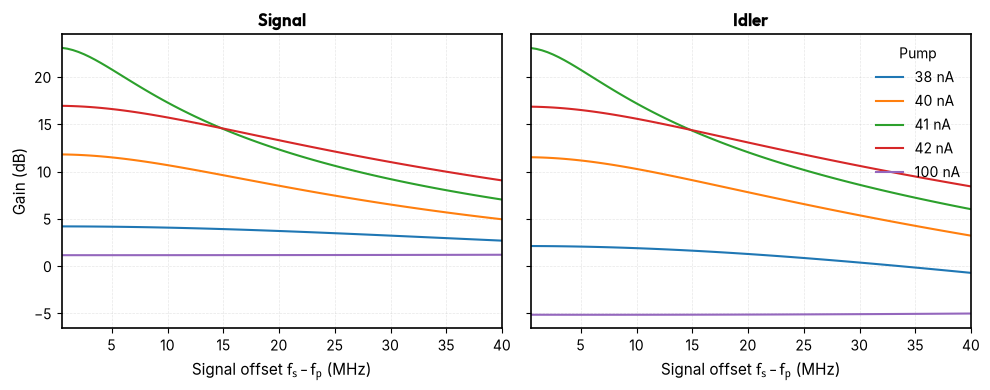

In [5]:
F_PUMP_KERR = 5.84e9
KERR_LOADS = ["josephson_junction.va", "capacitor.osdi", "resistor.osdi"]


def kerr_circuit(pump_source: str) -> str:
    """Kerr JPA circuit with the given pump source parameters."""
    return f"""
        model isource isource
        model resistor resistor
        model capacitor capacitor
        model jj jj

        ipump (0 in) isource dc=0 {pump_source}
        rpump (in 0) resistor r={R_PORT}
        cc (in 1) capacitor c=0.185e-12
        j1 (1 0) jj ic={IC}
        c1 (1 0) capacitor c={C_SHUNT}
    """


ac = vacask.run(
    Netlist(
        "Unpumped Kerr JPA",
        loads=KERR_LOADS,
        circuit=kerr_circuit(f"mag={I_SIG}"),
        control=f'{OPTIONS}\nanalysis ac1 ac from=5e9 to=7e9 mode="lin" points=200001',
    )
)["ac1"]
f0_kerr, kappa_kerr = resonance(
    jnp.asarray(ac["frequency"].real), reflection(ac["in"], I_SIG)
)
print(
    f"unpumped f0 = {f0_kerr / 1e9:.4f} GHz, κ/2π = {kappa_kerr / 1e6:.1f} MHz, "
    f"pump detuning (f_p - f0)/(κ/2π) = {(F_PUMP_KERR - f0_kerr) / kappa_kerr:.2f}"
)

KERR_PUMP = (
    f'type="sine" sinedc=0 ampl=40e-9 freq={F_PUMP_KERR} spur={{[1]}} smag=[{I_SIG}]'
)
pumps = [38e-9, 40e-9, 41e-9, 42e-9, 100e-9]
circuit = Netlist(
    "Kerr JPA",
    loads=KERR_LOADS,
    circuit=kerr_circuit(KERR_PUMP),
    control=f"""
        {OPTIONS}
        sweep pump instance="ipump" parameter="ampl" values={format_value(pumps)}
        analysis hbac1 hbac freq=[{F_PUMP_KERR}] nharm=7 outspur={format_value([[k] for k in range(-7, 8, 2)])} \\
            from=0.5e6 to=40e6 mode="lin" points=79
    """,
)
start = time.perf_counter()
plot = vacask.run(circuit)["hbac1"]
print(f"5 pump amplitudes × 80 offsets in {time.perf_counter() - start:.2f} s")

fig, (ax, ax_idler) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for group in plot.split("pump"):
    offset = jnp.asarray(group["frequency"].real)
    gain = db(reflection(group["in;1"], I_SIG))
    idler = db(conversion(group["in;-1"], I_SIG))
    f_signal = F_PUMP_KERR + offset[0]
    photon_sum = sum(
        jnp.sign(offset[0] + k * F_PUMP_KERR)
        * jnp.abs((reflection if k == 1 else conversion)(group[f"in;{k}"][0], I_SIG))
        ** 2
        * f_signal
        / jnp.abs(offset[0] + k * F_PUMP_KERR)
        for k in range(-7, 8, 2)
    )
    i5 = jnp.argmin(jnp.abs(offset - 5e6))
    label = f"{group['pump'][0].real * 1e9:.0f} nA"
    print(
        f"I_p = {group['pump'][0].real * 1e9:5.1f} nA: "
        f"G = {gain[0]:6.2f} dB, idler {idler[0]:6.2f} dB at 0.5 MHz; "
        f"G = {gain[i5]:6.2f} dB at 5 MHz; "
        f"signed photon sum = {photon_sum:.6f}"
    )
    ax.plot(offset / 1e6, gain, label=label)
    ax_idler.plot(offset / 1e6, idler, label=label)
ax.set_xlabel(r"Signal offset $f_\text{s} - f_\text{p}$ (MHz)")
ax.set_ylabel("Gain (dB)")
ax.set_title("Signal")
ax_idler.set_xlabel(r"Signal offset $f_\text{s} - f_\text{p}$ (MHz)")
ax_idler.set_title("Idler")
ax_idler.legend(title="Pump")
fig.tight_layout()
show_plot()

Photon flux should obey the Manley-Rowe balance
{cite:p}`manleyGeneralPropertiesNonlinear1956`:

$$\sum_k \operatorname{sign}(f_k)\,|S_{k\text{s}}|^2
\frac{f_\text{s}}{|f_k|} \simeq 1, \qquad
f_k = \delta f + k f_\text{p}.$$

Only the signal sideband subtracts the incident wave; the others carry no
incident wave. Negative-frequency sidebands count with a minus sign because the
pump amplifies into them. The sum stays within $2\times10^{-5}$ of 1 at every
pump, so the odd sidebands up to $k=\pm7$ capture the mixing. The residual
also includes the small junction dissipation. The balance does not test pump
stability.

Gain is not monotonic in pump power. The Kerr shift of
Eq. {eq}`eq:vacask-kerr-inductance` pulls the resonance down toward the pump,
and the gain peaks between 41 and 42 nA, where the pumped resonance crosses
the pump. A stronger pump overshoots, and at 100 nA the gain falls to about
1 dB. The pump detuning is below $\sqrt3\,\kappa/2$, the critical detuning
of a Kerr oscillator, so the pumped state stays single-valued and the gain
stays finite {cite:p}`eichlerControllingDynamicRange2014`. A pump detuned
further would reach a bistable region instead.

## Flux-pumped JPA

A SQUID terminates a resonator. The pump modulates its flux at
$f_\text{p}\approx2f_0$
{cite:p}`yamamotoFluxdrivenJosephsonParametric2008`. A signal at
$f_\text{s}$ is amplified with an idler at $f_\text{p}-f_\text{s}$. This is
three-wave mixing.

We treat the symmetric SQUID as one junction with
$I_\text{c,tot}\cos(\pi\Phi/\Phi_0)$. This neglects loop inductance, valid
for $\beta_L=2L_\text{loop}I_\text{c}/\Phi_0\ll1$
{cite:p}`tescheDcSQUIDNoise1977`. The flux is the third terminal voltage in
units of $\Phi_0$.

### Lumped flux-pumped JPA

The Kerr circuit with the junction replaced by a SQUID
($I_\text{c,tot}=2$ µA). Its inductance
$L_\text{S}(\Phi)=\Phi_0/(2\pi I_\text{c,tot}|\cos\pi\Phi/\Phi_0|)$ tunes the
resonance. A flux pump $\Phi_\text{p}\cos\omega_\text{p}t$ around the bias
modulates the resonance frequency by
$\delta\omega=2\pi\,|\text{d}f_0/\text{d}\Phi|\,\Phi_\text{p}$. The pump does
not drive the resonator directly, so it causes almost no Kerr shift.

Single-mode theory {cite:p}`royIntroductionParametricAmplification2016` gives
the threshold $\delta\omega=\kappa$ and the phase-preserving gain at
$f_\text{s}\to f_\text{p}/2$:

```{math}
:label: eq:vacask-lumped-3wm-gain
G_0 = \left(\frac{1 + r^2}{1 - r^2}\right)^2, \qquad r = \frac{\delta\omega}{\kappa}.
```

Above about 10 dB the gain is close to a Lorentzian in signal detuning with
full width $B$, and $\sqrt{G_0}\,B\to\kappa/2\pi$.

The bias is $0.3\,\Phi_0$ and the pump is at 12.9358 GHz, within 0.01κ of
$2f_0$. An unpumped AC sweep gives $f_0$, $\kappa$ and
$\text{d}f_0/\text{d}\Phi$. The signal is injected on the zeroth sideband
(`spur={[0]}`). The `hbac` sweep variable is then the absolute signal
frequency, and the idler is `in;-1`. The grid skips the degenerate point
$f_\text{s}=f_\text{p}/2$, where the gain depends on the signal phase.

f0 = 6.4661 GHz, κ/2π = 183.0 MHz, df0/dΦ = -14.10 GHz/Φ0, single-mode threshold 0.0130 Φ0


pump 0.002 Φ0 (r = 0.15): peak  0.41 dB (single-mode  0.41 dB), 3 dB bandwidth 200.0 MHz, √G·B / (κ/2π) = 1.15
pump 0.005 Φ0 (r = 0.39): peak  2.58 dB (single-mode  2.60 dB), 3 dB bandwidth 200.0 MHz, √G·B / (κ/2π) = 1.47
pump 0.008 Φ0 (r = 0.62): peak  6.88 dB (single-mode  6.95 dB), 3 dB bandwidth  86.0 MHz, √G·B / (κ/2π) = 1.04


pump 0.010 Φ0 (r = 0.77): peak 11.73 dB (single-mode 11.87 dB), 3 dB bandwidth  45.0 MHz, √G·B / (κ/2π) = 0.95
pump 0.011 Φ0 (r = 0.85): peak 15.49 dB (single-mode 15.71 dB), 3 dB bandwidth  29.0 MHz, √G·B / (κ/2π) = 0.94
pump 0.012 Φ0 (r = 0.92): peak 21.66 dB (single-mode 22.13 dB), 3 dB bandwidth  14.0 MHz, √G·B / (κ/2π) = 0.93


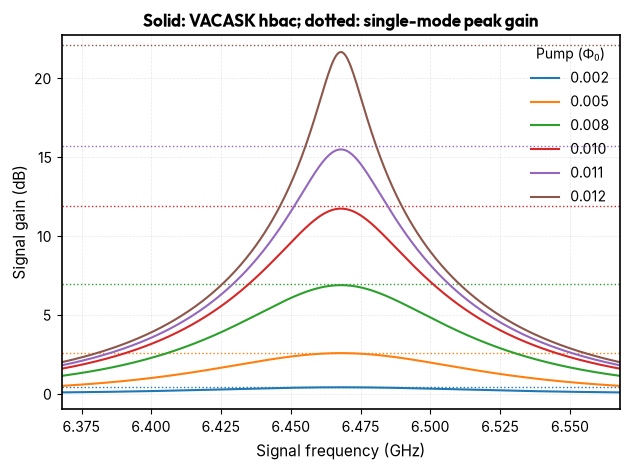

In [6]:
F_PUMP_LUMPED = 12.9358e9
SQUID_LOADS = ["squid.va", "capacitor.osdi", "resistor.osdi"]
SMALL_SIGNAL = f"mag=1e-9 spur={{[0]}} smag=[{I_SIG}]"


def lumped_circuit(source: str = SMALL_SIGNAL, pump: float = 0.01) -> str:
    """Lumped flux-pumped JPA circuit."""
    return f"""
        model isource isource
        model vsource vsource
        model resistor resistor
        model capacitor capacitor
        model squid squid

        iin (0 in) isource dc=0 {source}
        rport (in 0) resistor r={R_PORT}
        cc (in 1) capacitor c=0.185e-12
        s1 (1 0 fl) squid ic_tot=2e-6
        c1 (1 0) capacitor c={C_SHUNT}
        vfl (fl 0) vsource type="sine" sinedc=0.3 ampl={pump} freq={F_PUMP_LUMPED}
    """


FLUX_BIAS = 0.3
ac = vacask.run(
    Netlist(
        "Unpumped flux-pumped JPA",
        loads=SQUID_LOADS,
        circuit=lumped_circuit(f"mag={I_SIG}", pump=0.0),
        control=f"""
            {OPTIONS}
            sweep flux instance="vfl" parameter="sinedc" \\
                values={format_value([FLUX_BIAS - 1e-3, FLUX_BIAS, FLUX_BIAS + 1e-3])}
            analysis ac1 ac from=5.5e9 to=7.5e9 mode="lin" points=200001
        """,
    )
)["ac1"]
(f_lo, _), (F0_LUMPED, KAPPA_LUMPED), (f_hi, _) = (
    resonance(jnp.asarray(g["frequency"].real), reflection(g["in"], I_SIG))
    for g in ac.split("flux")
)
df0_dphi = (f_hi - f_lo) / 2e-3
threshold = KAPPA_LUMPED / abs(df0_dphi)
print(
    f"f0 = {F0_LUMPED / 1e9:.4f} GHz, κ/2π = {KAPPA_LUMPED / 1e6:.1f} MHz, "
    f"df0/dΦ = {df0_dphi / 1e9:.2f} GHz/Φ0, single-mode threshold {threshold:.4f} Φ0"
)

pumps_flux = [0.002, 0.005, 0.008, 0.010, 0.011, 0.012]
circuit = Netlist(
    "Flux-pumped JPA",
    loads=SQUID_LOADS,
    circuit=lumped_circuit(),
    control=f"""
        {OPTIONS}
        sweep pump instance="vfl" parameter="ampl" values={format_value(pumps_flux)}
        analysis hbac1 hbac freq=[{F_PUMP_LUMPED}] nharm=5 outspur={{[0],[-1]}} \\
            from=6.3679e9 to=6.5679e9 mode="lin" points=400
    """,
)
plot = vacask.run(circuit)["hbac1"]

fig, ax = plt.subplots()
for group in plot.split("pump"):
    f = jnp.asarray(group["frequency"].real)
    gain = db(reflection(group["in;0"], I_SIG))
    k = gain.argmax()
    above = f[gain >= gain[k] - 3]
    bandwidth = above.max() - above.min()
    gbw = 10 ** (gain[k] / 20) * bandwidth
    r = group["pump"][0].real / threshold
    single_mode = 20 * jnp.log10((1 + r**2) / (1 - r**2))
    print(
        f"pump {group['pump'][0].real:.3f} Φ0 (r = {r:.2f}): peak {gain[k]:5.2f} dB "
        f"(single-mode {single_mode:5.2f} dB), 3 dB bandwidth {bandwidth / 1e6:5.1f} MHz, "
        f"√G·B / (κ/2π) = {gbw / KAPPA_LUMPED:.2f}"
    )
    (line,) = ax.plot(f / 1e9, gain, label=f"{group['pump'][0].real:.3f}")
    ax.axhline(float(single_mode), color=line.get_color(), ls=":", lw=1)
ax.set_xlabel("Signal frequency (GHz)")
ax.set_ylabel("Signal gain (dB)")
ax.legend(title=r"Pump ($\Phi_0$)")
ax.set_title("Solid: VACASK hbac; dotted: single-mode peak gain")
show_plot()

The peak gain follows Eq. {eq}`eq:vacask-lumped-3wm-gain` to within about
0.5 dB, even at 22 dB. Above 10 dB, $\sqrt{G}\,B$ is within 7 % of
$\kappa/2\pi$, the gain-bandwidth limit of a single-mode amplifier
{cite:p}`royIntroductionParametricAmplification2016,eichlerControllingDynamicRange2014`.
Below about 3 dB the 3 dB bandwidth is wider than the 200 MHz sweep, so the
product is not meaningful there. A lumped resonator has no higher modes for
the pump to couple into. Compare the
{doc}`CPW resonator <vacask_cpw_parametric_amplifier>`, whose gain falls well
short of the same formula.

## Compression

A two-tone `hb` run gives the large-signal gain. HB solves the full nonlinear
periodic steady state for a finite drive. This is not `hbac`, which assumes an
infinitesimal signal. Here the signal sits 5 MHz above $f_\text{p}/2$, the
pump is 0.011 $\Phi_0$, and the current is swept from 1 pA to 30 nA. The input
power is $P=(I_\text{s}R/2)^2/(2R)$. Saturation in SQUID JPAs is mostly set
by the Kerr shift rather than by pump depletion
{cite:p}`eichlerControllingDynamicRange2014`.

small-signal gain 15.00 dB, input P1dB ≈ -129.5 dBm


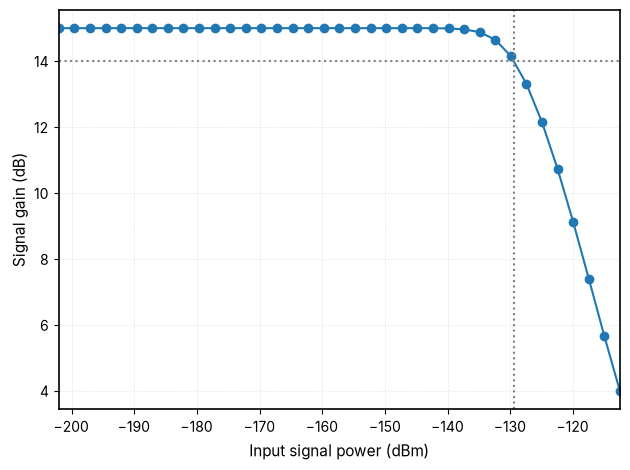

In [7]:
F_SIG = 6.4729e9
circuit = Netlist(
    "Flux-pumped JPA compression",
    loads=SQUID_LOADS,
    circuit=lumped_circuit(f'type="sine" sinedc=0 ampl=1e-12 freq={F_SIG}', pump=0.011),
    control=f"""
        {OPTIONS}
        sweep sig instance="iin" parameter="ampl" from=1e-12 to=30e-9 mode="dec" points=8
        analysis hb1 hb freq=[{F_PUMP_LUMPED}, {F_SIG}] nharm=[3, 5] immax=7
    """,
)
plot = vacask.run(circuit)["hb1"]

groups = plot.split("sig")
source_current = jnp.array([g["sig"][0].real for g in groups])
v_signal = jnp.array([
    g["in"][jnp.argmin(jnp.abs(jnp.asarray(g["frequency"].real) - F_SIG))]
    for g in groups
])
gain_large = db(v_signal / (-1j * source_current * R_PORT / 2) - 1)
power_dbm = 10 * jnp.log10((source_current * R_PORT / 2) ** 2 / (2 * R_PORT) / 1e-3)
p1db = jnp.interp(gain_large[0] - 1, gain_large[::-1], power_dbm[::-1])
print(f"small-signal gain {gain_large[0]:.2f} dB, input P1dB ≈ {p1db:.1f} dBm")

fig, ax = plt.subplots()
ax.plot(power_dbm, gain_large, "o-")
ax.axhline(float(gain_large[0] - 1), color="gray", ls=":")
ax.axvline(float(p1db), color="gray", ls=":")
ax.set_xlabel("Input signal power (dBm)")
ax.set_ylabel("Signal gain (dB)")
show_plot()

## Connect the lumped circuit to layout

QPDK has {func}`~qpdk.cells.junction.josephson_junction`, {func}`~qpdk.cells.junction.squid_junction` and {func}`~qpdk.cells.capacitor.interdigital_capacitor` cells. Their geometry is a starting point for these circuits. Junction overlap alone does not set the critical current without process calibration. Likewise, replace the ideal shunt and coupling capacitances with extracted values before predicting a fabricated device. The {doc}`capacitor extraction notebook <elmer_capacitance_interdigital>` shows that step. The {ref}`CPW example <vacask-cpw-layout>` shows how layout and circuit models can share geometry inputs.

## Limitations

- **Classical.** HB gives classical gain and conversion. It does not give
  added noise or squeezing ({cite:t}`clerkIntroductionQuantumNoise2010`;
  {cite:t}`royIntroductionParametricAmplification2016`). The junction shunt
  conductance is noiseless.
- **Threshold and stability.** `hbac` linearizes around the pumped state
  whether or not that state is stable. A flux-pumped JPA has a parametric
  threshold. There the pump-induced frequency modulation reaches the
  resonator linewidth. Above it the gain formula diverges and the reported
  gain is not physical. The threshold quoted here is the single-mode
  estimate from an unpumped AC sweep, not a stability analysis of the
  pumped state.
- **Junction model.** RCSJ keeps only the first Josephson harmonic
  {cite:p}`McCumber1968,tinkhamIntroductionSuperconductivity2015`, while real
  junctions show higher ones
  {cite:p}`willschObservationJosephsonHarmonics2024`. The SQUID model
  neglects loop inductance and asymmetry.
- **Compression.** The two-tone run fixes the pump and samples signal power.
  It shows saturation at those points. It does not establish pump depletion
  or stability.

## References

```{bibliography}
:filter: docname in docnames
```